# Movie Review Sentiment Analysis — Integrated four-member experiments
Run this notebook top to bottom in Google Colab with `IMDB Dataset.csv`. It integrates the exact model experiment cells from the four standalone notebooks; the individual files do not need to be executed first.

Use scikit-learn **1.6.1**, matching the existing `requirements.txt`. If needed, install it with `%pip install scikit-learn==1.6.1 wordcloud` in a separate setup cell and restart the runtime before running.

**Preserved:** original loading, EDA, cleaning, word clouds, outer 80/20 split, TF-IDF settings, comparison/evaluation cells, sample-review predictions and three-file frontend export. **Expanded:** the shared training cell is replaced by four independent tuning/evaluation sections plus results assembly. Validation uses an additional training-only split and separate vectorizer.

The final download cell writes `tfidf_vectorizer.joblib`, `all_models.joblib`, and `accuracies.joblib` with the same model-name keys expected by `app.py`. Replace all three files together after a successful complete run. No frontend edits are needed. Scores may change after tuning; update report numbers using the newly computed results.

All code cells below were executed on the full IMDb dataset with scikit-learn 1.6.1. Outputs are saved. Timings reflect this execution environment.

In [1]:
%matplotlib inline
import sklearn
print('scikit-learn version:', sklearn.__version__)
assert sklearn.__version__ == '1.6.1', 'Install scikit-learn==1.6.1 and restart the runtime to match the frontend.'

scikit-learn version: 1.6.1


## 1. Import libraries

In [2]:
import pandas as pd, numpy as np, re, joblib, sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
sns.set_style("whitegrid")

## 2. Load the dataset


In [3]:
# Colab upload/download UI; local execution uses the same CSV and writes files to disk.
try:
    from google.colab import files
except ImportError:
    from pathlib import Path
    class LocalFiles:
        @staticmethod
        def upload():
            if not Path("IMDB Dataset.csv").is_file():
                raise FileNotFoundError("Place IMDB Dataset.csv beside the notebook before running.")
            print("Using local IMDB Dataset.csv")
            return {}
        @staticmethod
        def download(filename):
            print("Saved:", filename)
    files = LocalFiles()
uploaded = files.upload()
df = pd.read_csv("IMDB Dataset.csv")
df.head()

Using local IMDB Dataset.csv


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 3. Exploratory Data Analysis (EDA)

### 3.1 Basic information

In [4]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate reviews:", df.duplicated().sum())
df.info()

Shape: (50000, 2)

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicate reviews: 418
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [5]:
# Remove duplicate reviews
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (49582, 2)


### 3.2 Class balance
Checking if positive and negative reviews are equal in number.

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


/workspace/scratch/ff7ada153b28/output/05_Integrated_All_Models.ipynb:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  "nbformat": 4,


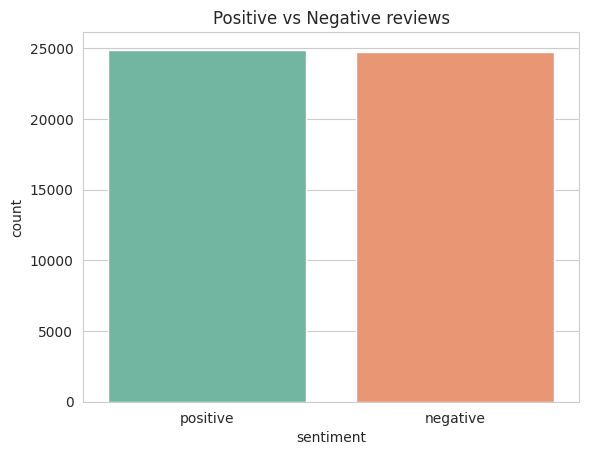

In [6]:
print(df["sentiment"].value_counts())
sns.countplot(x="sentiment", data=df, palette="Set2")
plt.title("Positive vs Negative reviews")
plt.show()

### 3.3 Review length
Do positive and negative reviews differ in length?

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


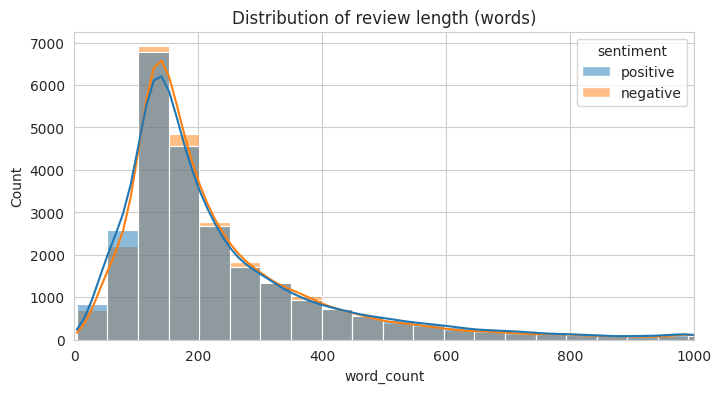

In [7]:
df["word_count"] = df["review"].apply(lambda x: len(x.split()))
print(df.groupby("sentiment")["word_count"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="word_count", hue="sentiment", bins=50, kde=True)
plt.xlim(0, 1000)
plt.title("Distribution of review length (words)")
plt.show()

## 4. Text preprocessing
Remove HTML tags (like `<br />`) and convert to lowercase. Stopwords are removed later by TF-IDF.

In [8]:
def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)
    return text.lower()

df["clean_review"] = df["review"].apply(clean_text)
df[["review", "clean_review"]].head(3)

,review,clean_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming t...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...


### 4.1 Word clouds
Most frequent words in positive and negative reviews.

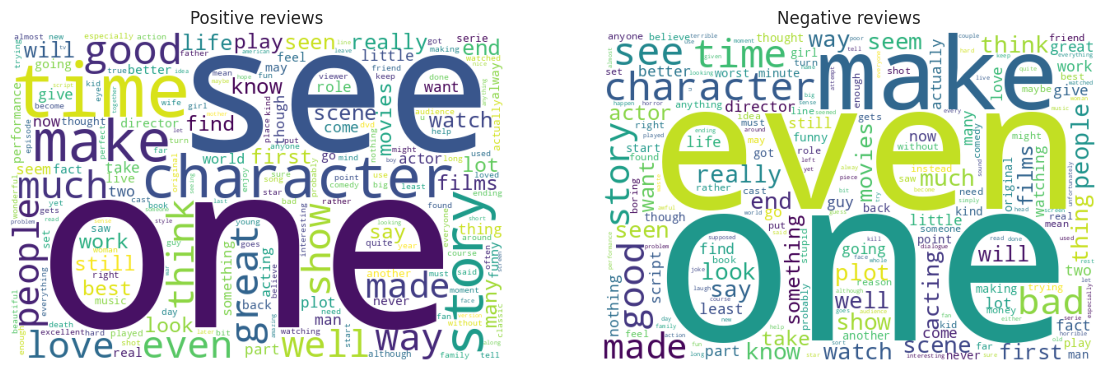

In [9]:
from wordcloud import WordCloud, STOPWORDS
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, label in enumerate(["positive", "negative"]):
    text = " ".join(df[df["sentiment"] == label]["clean_review"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   stopwords=STOPWORDS.union({"br", "movie", "film"})).generate(text)
    ax[i].imshow(wc)
    ax[i].set_title(label.capitalize() + " reviews")
    ax[i].axis("off")
plt.show()

## 5. Feature extraction using TF-IDF
TF-IDF converts text into numbers. We split the data 80% train / 20% test.

In [10]:
y = (df["sentiment"] == "positive").astype(int)   # positive = 1, negative = 0
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"], y, test_size=0.2, random_state=42, stratify=y)

vec = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
print("Train shape:", Xtr.shape, " Test shape:", Xte.shape)

Train shape: (39665, 20000)  Test shape: (9917, 20000)


## Validation setup for the four individual experiments
The original 80/20 split and final TF-IDF matrices above remain unchanged. For tuning only, split the 80% training reviews again into 75% subtraining and 25% validation (60/20/20 overall). A separate vectorizer learns only from subtraining text. Select by validation accuracy, then refit the selected configuration on the original full 80% training matrix. Never choose settings using test results. The final exported models all use the original `vec`.

In [11]:
from sklearn.base import clone
from time import perf_counter
from IPython.display import display

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)
tuning_vec = clone(vec)
Xsub = tuning_vec.fit_transform(X_subtrain)
Xval = tuning_vec.transform(X_val)
models, preds, accs = {}, {}, {}
results, timing_results, experiment_tables = [], [], {}
selected_settings = {}
print('Subtraining:', Xsub.shape, 'Validation:', Xval.shape)
print('Final training:', Xtr.shape, 'Untouched test:', Xte.shape)

Subtraining: (29748, 20000) Validation: (9917, 20000)
Final training: (39665, 20000) Untouched test: (9917, 20000)


## Model 1: Logistic Regression
**Individual contribution:** baseline, three-setting validation experiment, training/validation graph, selected-model test evaluation, confusion matrix, and incorrect-review examples.

Weighted text features; C controls inverse regularisation strength.

The original setting is included among the candidates. Improvements are not guaranteed; interpret the measured results. Saved results come from the full-dataset execution; rerunning regenerates them.

In [12]:
model_name = 'Logistic Regression'
parameter_name = 'C'
candidate_values = [0.1, 1.0, 10.0]
baseline_value = 1.0

def make_candidate(value):
    return LogisticRegression(C=value, max_iter=1000)

trial_rows = []
for value in candidate_values:
    candidate = make_candidate(value)
    started = perf_counter()
    candidate.fit(Xsub, y_subtrain)
    elapsed = perf_counter() - started
    train_pred = candidate.predict(Xsub)
    val_pred = candidate.predict(Xval)
    trial_rows.append({
        parameter_name: value,
        'Training accuracy': accuracy_score(y_subtrain, train_pred),
        'Validation accuracy': accuracy_score(y_val, val_pred),
        'Validation F1': f1_score(y_val, val_pred),
        'Training seconds': elapsed,
        'Original setting': value == baseline_value
    })
trials = pd.DataFrame(trial_rows)
experiment_tables[model_name] = trials.copy()
display(trials.round(4))
# First candidate wins an exact tie; no test scores enter this decision.
best_index = int(np.argmax(trials['Validation accuracy'].to_numpy()))
best_value = candidate_values[best_index]
selected_settings[model_name] = {parameter_name: best_value}
print('Selected using validation accuracy:', selected_settings[model_name])

Selected using validation accuracy: {'C': 1.0}


,C,Training accuracy,Validation accuracy,Validation F1,Training seconds,Original setting
0,0.1,0.8799,0.8625,0.8672,0.2289,False
1,1.0,0.9320,0.8932,0.8952,0.2710,True
2,10.0,0.9816,0.8904,0.8921,0.6054,False


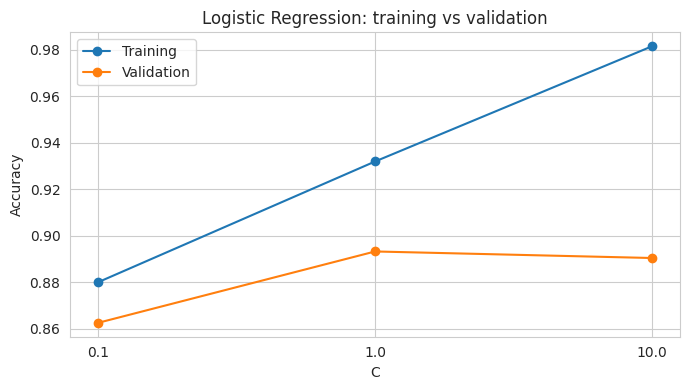

In [13]:
positions = np.arange(len(candidate_values))
plt.figure(figsize=(7, 4))
plt.plot(positions, trials['Training accuracy'], marker='o', label='Training')
plt.plot(positions, trials['Validation accuracy'], marker='o', label='Validation')
plt.xticks(positions, [str(v) for v in candidate_values])
plt.xlabel(parameter_name)
plt.ylabel('Accuracy')
plt.title(model_name + ': training vs validation')
plt.legend()
plt.tight_layout()
plt.show()

### Refit the selected configuration and evaluate once on the test set
Refitting uses the original full-training `Xtr` and its original vectorizer. Metrics below describe the selected model on held-out test reviews, not the tuning subset.

              precision    recall  f1-score   support

    Negative       0.91      0.88      0.89      4940
    Positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8966,0.8856,0.9118,0.8985


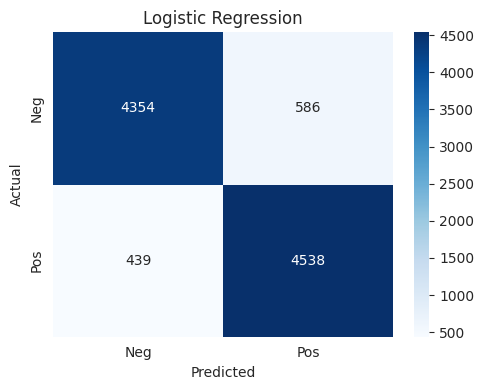

In [14]:
final_model = make_candidate(best_value)
started = perf_counter()
final_model.fit(Xtr, y_train)
fit_seconds = perf_counter() - started
started = perf_counter()
p = final_model.predict(Xte)
predict_seconds = perf_counter() - started
models[model_name] = final_model
preds[model_name] = p
accs[model_name] = round(accuracy_score(y_test, p), 4)
results.append([model_name, accuracy_score(y_test, p),
                precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])
timing_results.append({'Model': model_name, 'Training seconds': fit_seconds,
                       'Test prediction seconds': predict_seconds})
display(pd.DataFrame([results[-1]], columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(4))
print(classification_report(y_test, p, target_names=['Negative', 'Positive']))
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, p, labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
plt.title(model_name)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [15]:
# Positional arrays avoid index alignment issues after the split.
error_table = pd.DataFrame({
    'Review': X_test.to_numpy(), 'Actual': y_test.to_numpy(), 'Predicted': p})
errors = error_table[error_table['Actual'] != error_table['Predicted']].copy()
errors['Actual'] = errors['Actual'].map({0: 'Negative', 1: 'Positive'})
errors['Predicted'] = errors['Predicted'].map({0: 'Negative', 1: 'Positive'})
print('Incorrect predictions:', len(errors), 'out of', len(y_test))
with pd.option_context('display.max_colwidth', 350):
    display(errors.head(5))

Incorrect predictions: 1025 out of 9917


,Review,Actual,Predicted
24,"despite being a huge fan of fred astaire and ginger rogers' movies, it wasn't until about 6 years ago that i first saw 'follow the fleet'. i knew all the songs from an old astaire/rogers record (yes, vinyl) but knew nothing of the plot. unfortunately, while the songs are catchy and ginger rogers' character is sweet and funny, you just can't li...",Negative,Positive
35,"well, well....roeg touched a bit of a nerve there, didn't he? he was a genius while he was cataloguing his various characters' descents into psychosis for a couple of decades, but as soon as he has the bad taste to suggest that redemption (or even some good advice) might be found in the bad old catholic church, the hipper-than-thou alternative ...",Positive,Negative
43,"ok, let me again admit that i haven't seen any other merchant ivory (the distributor) films. nor have i seen more celebrated works by the director, so my capacity to discuss before the rains outside of analysis of the film itself is mitigated. with that admittance, let me begin. before the rains is a different kind of movie that doesn't know w...",Negative,Positive
45,"i'm not here to tell you ""armored"" is kubrickian, hitchcockian or fellini-esquire. nope. referenced directors are more like don siegel (""charlie varrick"") and walter hill (""the warriors""). those two helmers didn't fool around with niceties like putting women in their movies. no skirts need apply. they unapologetically made guy movies. guns, lot...",Positive,Negative
53,"i'm not a big fan of rom/coms at the best of times. a few have been quite good (check of dream for an insomniac), but this one is just more of the same but less. with a running time of 100min, i expect more than 1 laugh every 30mins. the only real belly laugh are when male strangers and friends instinctively help out lee's character. all i ca...",Negative,Positive


### Explain your findings
After running, state: (1) which setting won on validation; (2) whether training and validation scores diverged; (3) final test metrics; (4) patterns you actually observe in the incorrect reviews. Do not claim an improvement or a cause of errors without evidence. Do not retune after reading test errors. Timing depends on the runtime hardware.

## Model 2: Naive Bayes
**Individual contribution:** baseline, three-setting validation experiment, training/validation graph, selected-model test evaluation, confusion matrix, and incorrect-review examples.

Probabilistic text classification; alpha controls additive smoothing.

The original setting is included among the candidates. Improvements are not guaranteed; interpret the measured results. Saved results come from the full-dataset execution; rerunning regenerates them.

In [16]:
model_name = 'Naive Bayes'
parameter_name = 'alpha'
candidate_values = [0.1, 0.5, 1.0]
baseline_value = 1.0

def make_candidate(value):
    return MultinomialNB(alpha=value)

trial_rows = []
for value in candidate_values:
    candidate = make_candidate(value)
    started = perf_counter()
    candidate.fit(Xsub, y_subtrain)
    elapsed = perf_counter() - started
    train_pred = candidate.predict(Xsub)
    val_pred = candidate.predict(Xval)
    trial_rows.append({
        parameter_name: value,
        'Training accuracy': accuracy_score(y_subtrain, train_pred),
        'Validation accuracy': accuracy_score(y_val, val_pred),
        'Validation F1': f1_score(y_val, val_pred),
        'Training seconds': elapsed,
        'Original setting': value == baseline_value
    })
trials = pd.DataFrame(trial_rows)
experiment_tables[model_name] = trials.copy()
display(trials.round(4))
# First candidate wins an exact tie; no test scores enter this decision.
best_index = int(np.argmax(trials['Validation accuracy'].to_numpy()))
best_value = candidate_values[best_index]
selected_settings[model_name] = {parameter_name: best_value}
print('Selected using validation accuracy:', selected_settings[model_name])

Selected using validation accuracy: {'alpha': 1.0}


,alpha,Training accuracy,Validation accuracy,Validation F1,Training seconds,Original setting
0,0.1,0.8969,0.8622,0.8643,0.0082,False
1,0.5,0.8947,0.8640,0.8662,0.0078,False
2,1.0,0.8929,0.8644,0.8663,0.0078,True


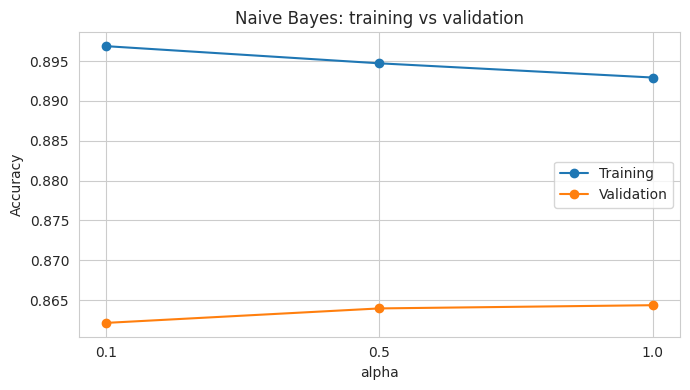

In [17]:
positions = np.arange(len(candidate_values))
plt.figure(figsize=(7, 4))
plt.plot(positions, trials['Training accuracy'], marker='o', label='Training')
plt.plot(positions, trials['Validation accuracy'], marker='o', label='Validation')
plt.xticks(positions, [str(v) for v in candidate_values])
plt.xlabel(parameter_name)
plt.ylabel('Accuracy')
plt.title(model_name + ': training vs validation')
plt.legend()
plt.tight_layout()
plt.show()

### Refit the selected configuration and evaluate once on the test set
Refitting uses the original full-training `Xtr` and its original vectorizer. Metrics below describe the selected model on held-out test reviews, not the tuning subset.

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87      4940
    Positive       0.86      0.88      0.87      4977

    accuracy                           0.87      9917
   macro avg       0.87      0.87      0.87      9917
weighted avg       0.87      0.87      0.87      9917



,Model,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,0.8699,0.863,0.8807,0.8717


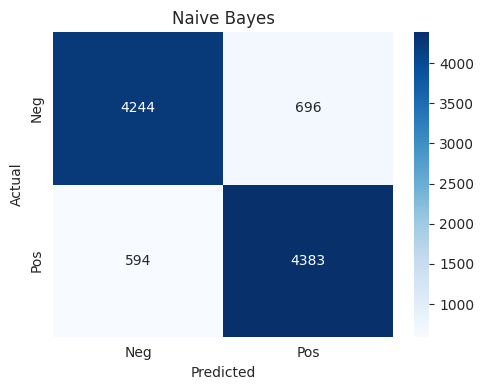

In [18]:
final_model = make_candidate(best_value)
started = perf_counter()
final_model.fit(Xtr, y_train)
fit_seconds = perf_counter() - started
started = perf_counter()
p = final_model.predict(Xte)
predict_seconds = perf_counter() - started
models[model_name] = final_model
preds[model_name] = p
accs[model_name] = round(accuracy_score(y_test, p), 4)
results.append([model_name, accuracy_score(y_test, p),
                precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])
timing_results.append({'Model': model_name, 'Training seconds': fit_seconds,
                       'Test prediction seconds': predict_seconds})
display(pd.DataFrame([results[-1]], columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(4))
print(classification_report(y_test, p, target_names=['Negative', 'Positive']))
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, p, labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
plt.title(model_name)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [19]:
# Positional arrays avoid index alignment issues after the split.
error_table = pd.DataFrame({
    'Review': X_test.to_numpy(), 'Actual': y_test.to_numpy(), 'Predicted': p})
errors = error_table[error_table['Actual'] != error_table['Predicted']].copy()
errors['Actual'] = errors['Actual'].map({0: 'Negative', 1: 'Positive'})
errors['Predicted'] = errors['Predicted'].map({0: 'Negative', 1: 'Positive'})
print('Incorrect predictions:', len(errors), 'out of', len(y_test))
with pd.option_context('display.max_colwidth', 350):
    display(errors.head(5))

Incorrect predictions: 1290 out of 9917


,Review,Actual,Predicted
15,"this isn't exactly a great film, but i admire the writers and director for trying something a little different. the film's main theme is fate and small, seemingly insignificant things that can greatly change the future. in some ways this reminds me of the film sliding doors, though instead of focusing on one random event, seemingly random stuff...",Positive,Negative
24,"despite being a huge fan of fred astaire and ginger rogers' movies, it wasn't until about 6 years ago that i first saw 'follow the fleet'. i knew all the songs from an old astaire/rogers record (yes, vinyl) but knew nothing of the plot. unfortunately, while the songs are catchy and ginger rogers' character is sweet and funny, you just can't li...",Negative,Positive
43,"ok, let me again admit that i haven't seen any other merchant ivory (the distributor) films. nor have i seen more celebrated works by the director, so my capacity to discuss before the rains outside of analysis of the film itself is mitigated. with that admittance, let me begin. before the rains is a different kind of movie that doesn't know w...",Negative,Positive
45,"i'm not here to tell you ""armored"" is kubrickian, hitchcockian or fellini-esquire. nope. referenced directors are more like don siegel (""charlie varrick"") and walter hill (""the warriors""). those two helmers didn't fool around with niceties like putting women in their movies. no skirts need apply. they unapologetically made guy movies. guns, lot...",Positive,Negative
51,"this movie probably had a $750 budget, and still managed to surpass titanic. i rented this the day i crashed my mom's car, and it was the only thing that cheered me up beyond belief! it has to be tied with 'the assult of the killer bimbos'. things to look for are: 1. the drive in blow job chinese girl scene 2. the bleach blonde in the sassoon s...",Positive,Negative


### Explain your findings
After running, state: (1) which setting won on validation; (2) whether training and validation scores diverged; (3) final test metrics; (4) patterns you actually observe in the incorrect reviews. Do not claim an improvement or a cause of errors without evidence. Do not retune after reading test errors. Timing depends on the runtime hardware.

## Model 3: Linear SVM
**Individual contribution:** baseline, three-setting validation experiment, training/validation graph, selected-model test evaluation, confusion matrix, and incorrect-review examples.

Linear separating boundary; C controls the penalty for margin violations.

The original setting is included among the candidates. Improvements are not guaranteed; interpret the measured results. Saved results come from the full-dataset execution; rerunning regenerates them.

In [20]:
model_name = 'Linear SVM'
parameter_name = 'C'
candidate_values = [0.1, 1.0, 10.0]
baseline_value = 1.0

def make_candidate(value):
    return LinearSVC(C=value, random_state=42)

trial_rows = []
for value in candidate_values:
    candidate = make_candidate(value)
    started = perf_counter()
    candidate.fit(Xsub, y_subtrain)
    elapsed = perf_counter() - started
    train_pred = candidate.predict(Xsub)
    val_pred = candidate.predict(Xval)
    trial_rows.append({
        parameter_name: value,
        'Training accuracy': accuracy_score(y_subtrain, train_pred),
        'Validation accuracy': accuracy_score(y_val, val_pred),
        'Validation F1': f1_score(y_val, val_pred),
        'Training seconds': elapsed,
        'Original setting': value == baseline_value
    })
trials = pd.DataFrame(trial_rows)
experiment_tables[model_name] = trials.copy()
display(trials.round(4))
# First candidate wins an exact tie; no test scores enter this decision.
best_index = int(np.argmax(trials['Validation accuracy'].to_numpy()))
best_value = candidate_values[best_index]
selected_settings[model_name] = {parameter_name: best_value}
print('Selected using validation accuracy:', selected_settings[model_name])

Selected using validation accuracy: {'C': 0.1}


,C,Training accuracy,Validation accuracy,Validation F1,Training seconds,Original setting
0,0.1,0.935,0.8945,0.8967,0.4656,False
1,1.0,0.987,0.8868,0.8883,0.5973,True
2,10.0,1.000,0.8628,0.8641,1.2589,False


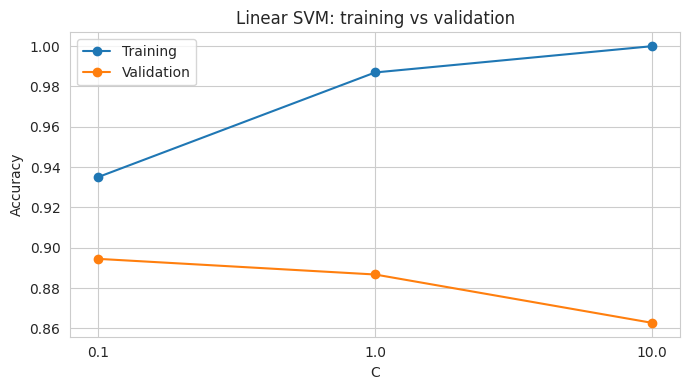

In [21]:
positions = np.arange(len(candidate_values))
plt.figure(figsize=(7, 4))
plt.plot(positions, trials['Training accuracy'], marker='o', label='Training')
plt.plot(positions, trials['Validation accuracy'], marker='o', label='Validation')
plt.xticks(positions, [str(v) for v in candidate_values])
plt.xlabel(parameter_name)
plt.ylabel('Accuracy')
plt.title(model_name + ': training vs validation')
plt.legend()
plt.tight_layout()
plt.show()

### Refit the selected configuration and evaluate once on the test set
Refitting uses the original full-training `Xtr` and its original vectorizer. Metrics below describe the selected model on held-out test reviews, not the tuning subset.

              precision    recall  f1-score   support

    Negative       0.91      0.88      0.90      4940
    Positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.8972,0.8862,0.9124,0.8991


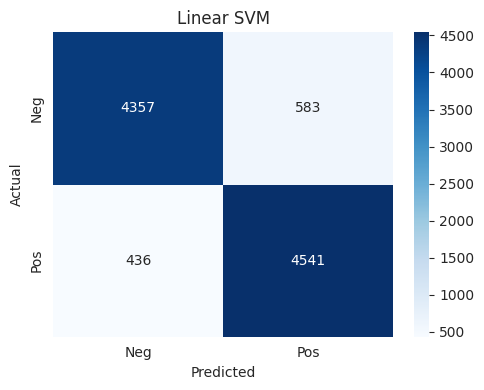

In [22]:
final_model = make_candidate(best_value)
started = perf_counter()
final_model.fit(Xtr, y_train)
fit_seconds = perf_counter() - started
started = perf_counter()
p = final_model.predict(Xte)
predict_seconds = perf_counter() - started
models[model_name] = final_model
preds[model_name] = p
accs[model_name] = round(accuracy_score(y_test, p), 4)
results.append([model_name, accuracy_score(y_test, p),
                precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])
timing_results.append({'Model': model_name, 'Training seconds': fit_seconds,
                       'Test prediction seconds': predict_seconds})
display(pd.DataFrame([results[-1]], columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(4))
print(classification_report(y_test, p, target_names=['Negative', 'Positive']))
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, p, labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
plt.title(model_name)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [23]:
# Positional arrays avoid index alignment issues after the split.
error_table = pd.DataFrame({
    'Review': X_test.to_numpy(), 'Actual': y_test.to_numpy(), 'Predicted': p})
errors = error_table[error_table['Actual'] != error_table['Predicted']].copy()
errors['Actual'] = errors['Actual'].map({0: 'Negative', 1: 'Positive'})
errors['Predicted'] = errors['Predicted'].map({0: 'Negative', 1: 'Positive'})
print('Incorrect predictions:', len(errors), 'out of', len(y_test))
with pd.option_context('display.max_colwidth', 350):
    display(errors.head(5))

Incorrect predictions: 1019 out of 9917


,Review,Actual,Predicted
24,"despite being a huge fan of fred astaire and ginger rogers' movies, it wasn't until about 6 years ago that i first saw 'follow the fleet'. i knew all the songs from an old astaire/rogers record (yes, vinyl) but knew nothing of the plot. unfortunately, while the songs are catchy and ginger rogers' character is sweet and funny, you just can't li...",Negative,Positive
35,"well, well....roeg touched a bit of a nerve there, didn't he? he was a genius while he was cataloguing his various characters' descents into psychosis for a couple of decades, but as soon as he has the bad taste to suggest that redemption (or even some good advice) might be found in the bad old catholic church, the hipper-than-thou alternative ...",Positive,Negative
43,"ok, let me again admit that i haven't seen any other merchant ivory (the distributor) films. nor have i seen more celebrated works by the director, so my capacity to discuss before the rains outside of analysis of the film itself is mitigated. with that admittance, let me begin. before the rains is a different kind of movie that doesn't know w...",Negative,Positive
45,"i'm not here to tell you ""armored"" is kubrickian, hitchcockian or fellini-esquire. nope. referenced directors are more like don siegel (""charlie varrick"") and walter hill (""the warriors""). those two helmers didn't fool around with niceties like putting women in their movies. no skirts need apply. they unapologetically made guy movies. guns, lot...",Positive,Negative
53,"i'm not a big fan of rom/coms at the best of times. a few have been quite good (check of dream for an insomniac), but this one is just more of the same but less. with a running time of 100min, i expect more than 1 laugh every 30mins. the only real belly laugh are when male strangers and friends instinctively help out lee's character. all i ca...",Negative,Positive


### Explain your findings
After running, state: (1) which setting won on validation; (2) whether training and validation scores diverged; (3) final test metrics; (4) patterns you actually observe in the incorrect reviews. Do not claim an improvement or a cause of errors without evidence. Do not retune after reading test errors. Timing depends on the runtime hardware.

## Model 4: Decision Tree
**Individual contribution:** baseline, three-setting validation experiment, training/validation graph, selected-model test evaluation, confusion matrix, and incorrect-review examples.

Feature-threshold decisions; maximum depth limits tree complexity.

The original setting is included among the candidates. Improvements are not guaranteed; interpret the measured results. Saved results come from the full-dataset execution; rerunning regenerates them.

In [24]:
model_name = 'Decision Tree'
parameter_name = 'max_depth'
candidate_values = [10, 25, 50]
baseline_value = 50

def make_candidate(value):
    return DecisionTreeClassifier(max_depth=value, random_state=42)

trial_rows = []
for value in candidate_values:
    candidate = make_candidate(value)
    started = perf_counter()
    candidate.fit(Xsub, y_subtrain)
    elapsed = perf_counter() - started
    train_pred = candidate.predict(Xsub)
    val_pred = candidate.predict(Xval)
    trial_rows.append({
        parameter_name: value,
        'Training accuracy': accuracy_score(y_subtrain, train_pred),
        'Validation accuracy': accuracy_score(y_val, val_pred),
        'Validation F1': f1_score(y_val, val_pred),
        'Training seconds': elapsed,
        'Original setting': value == baseline_value
    })
trials = pd.DataFrame(trial_rows)
experiment_tables[model_name] = trials.copy()
display(trials.round(4))
# First candidate wins an exact tie; no test scores enter this decision.
best_index = int(np.argmax(trials['Validation accuracy'].to_numpy()))
best_value = candidate_values[best_index]
selected_settings[model_name] = {parameter_name: best_value}
print('Selected using validation accuracy:', selected_settings[model_name])

Selected using validation accuracy: {'max_depth': 25}


,max_depth,Training accuracy,Validation accuracy,Validation F1,Training seconds,Original setting
0,10,0.7652,0.7233,0.7581,5.3698,False
1,25,0.8767,0.7321,0.7454,17.6764,False
2,50,0.9635,0.7215,0.7274,37.6238,True


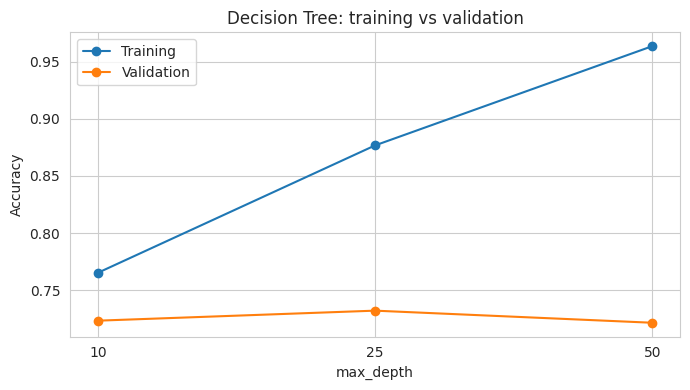

In [25]:
positions = np.arange(len(candidate_values))
plt.figure(figsize=(7, 4))
plt.plot(positions, trials['Training accuracy'], marker='o', label='Training')
plt.plot(positions, trials['Validation accuracy'], marker='o', label='Validation')
plt.xticks(positions, [str(v) for v in candidate_values])
plt.xlabel(parameter_name)
plt.ylabel('Accuracy')
plt.title(model_name + ': training vs validation')
plt.legend()
plt.tight_layout()
plt.show()

### Refit the selected configuration and evaluate once on the test set
Refitting uses the original full-training `Xtr` and its original vectorizer. Metrics below describe the selected model on held-out test reviews, not the tuning subset.

              precision    recall  f1-score   support

    Negative       0.78      0.68      0.73      4940
    Positive       0.72      0.81      0.76      4977

    accuracy                           0.74      9917
   macro avg       0.75      0.74      0.74      9917
weighted avg       0.75      0.74      0.74      9917



,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.744,0.7171,0.8089,0.7603


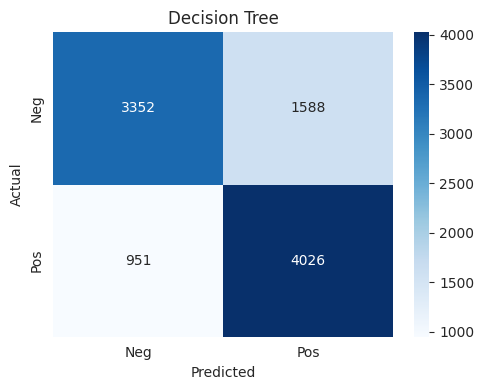

In [26]:
final_model = make_candidate(best_value)
started = perf_counter()
final_model.fit(Xtr, y_train)
fit_seconds = perf_counter() - started
started = perf_counter()
p = final_model.predict(Xte)
predict_seconds = perf_counter() - started
models[model_name] = final_model
preds[model_name] = p
accs[model_name] = round(accuracy_score(y_test, p), 4)
results.append([model_name, accuracy_score(y_test, p),
                precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])
timing_results.append({'Model': model_name, 'Training seconds': fit_seconds,
                       'Test prediction seconds': predict_seconds})
display(pd.DataFrame([results[-1]], columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(4))
print(classification_report(y_test, p, target_names=['Negative', 'Positive']))
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, p, labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
plt.title(model_name)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [27]:
# Positional arrays avoid index alignment issues after the split.
error_table = pd.DataFrame({
    'Review': X_test.to_numpy(), 'Actual': y_test.to_numpy(), 'Predicted': p})
errors = error_table[error_table['Actual'] != error_table['Predicted']].copy()
errors['Actual'] = errors['Actual'].map({0: 'Negative', 1: 'Positive'})
errors['Predicted'] = errors['Predicted'].map({0: 'Negative', 1: 'Positive'})
print('Incorrect predictions:', len(errors), 'out of', len(y_test))
with pd.option_context('display.max_colwidth', 350):
    display(errors.head(5))

Incorrect predictions: 2539 out of 9917


,Review,Actual,Predicted
5,"""saturday afternoon"" is one of harry langdon's best-known short subjects, and with good reason. it is one of his funniest and best films. the plot -- such as it is -- is an old staple: a hen-pecked husband sneaks away for a night out with a his pal and a couple of other girls. it's a solid and well-used comedy plot, but the difference here is h...",Positive,Negative
19,"fantastically putrid. i don't mean to imply above that only a few people should avoid ""doc savage."" almost every demographic group would be bored by this trivial, tv-movie-quality production. it's a little like the 60's ""batman"" tv series, except it's not funny. even accidentally. you're better off taking a nap.",Negative,Positive
21,"when the film started i got the feeling this was going to be something special. the acting and camera work were undoubtedly good. i also liked the characters and could have grown to empathise with them. the film had a good atmosphere and there was a hint of fantasy. however, as the film went on, the plot never appeared to takeoff and just roll...",Negative,Positive
23,"'a new generation' is the third amityville entry to base its plot around writer john g. jones's premise of an item taken from the long island house that causes spectral misery and death for its new owners. first a lamp, then a clock, and now a mirror. however, this is also the first amityville since 'the possession' to directly tie in to the re...",Negative,Positive
24,"despite being a huge fan of fred astaire and ginger rogers' movies, it wasn't until about 6 years ago that i first saw 'follow the fleet'. i knew all the songs from an old astaire/rogers record (yes, vinyl) but knew nothing of the plot. unfortunately, while the songs are catchy and ginger rogers' character is sweet and funny, you just can't li...",Negative,Positive


### Explain your findings
After running, state: (1) which setting won on validation; (2) whether training and validation scores diverged; (3) final test metrics; (4) patterns you actually observe in the incorrect reviews. Do not claim an improvement or a cause of errors without evidence. Do not retune after reading test errors. Timing depends on the runtime hardware.

## Assemble the four models for the original comparison and frontend

In [28]:
expected_names = ['Logistic Regression', 'Naive Bayes', 'Linear SVM', 'Decision Tree']
assert list(models) == expected_names
assert set(preds) == set(accs) == set(models)
assert all(m.n_features_in_ == Xtr.shape[1] for m in models.values())
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score'])
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)
display(results_df.round(4))
display(pd.DataFrame(timing_results).round(4))
print('Selected settings:', selected_settings)

Selected settings: {'Logistic Regression': {'C': 1.0}, 'Naive Bayes': {'alpha': 1.0}, 'Linear SVM': {'C': 0.1}, 'Decision Tree': {'max_depth': 25}}


,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.8972,0.8862,0.9124,0.8991
1,Logistic Regression,0.8966,0.8856,0.9118,0.8985
2,Naive Bayes,0.8699,0.8630,0.8807,0.8717
3,Decision Tree,0.7440,0.7171,0.8089,0.7603


,Model,Training seconds,Test prediction seconds
0,Logistic Regression,0.3095,0.0029
1,Naive Bayes,0.0100,0.0035
2,Linear SVM,0.6895,0.0031
3,Decision Tree,25.4070,0.0050


### 6.1 Accuracy comparison

/workspace/scratch/ff7ada153b28/output/05_Integrated_All_Models.ipynb:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  "nbformat": 4,


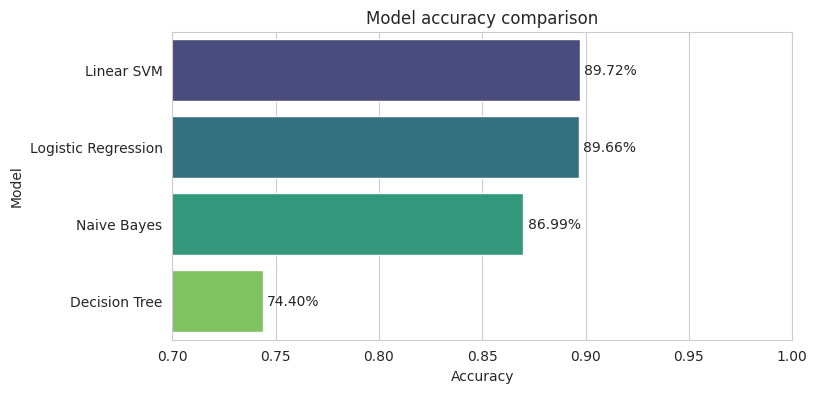

In [29]:
plt.figure(figsize=(8, 4))
sns.barplot(x="Accuracy", y="Model", data=results_df, palette="viridis")
plt.xlim(0.7, 1)
for i, v in enumerate(results_df["Accuracy"]):
    plt.text(v + 0.002, i, f"{v*100:.2f}%", va="center")
plt.title("Model accuracy comparison")
plt.show()

## 7. Evaluation

### 7.1 Confusion matrices
Shows how many reviews each model classified correctly and wrongly.

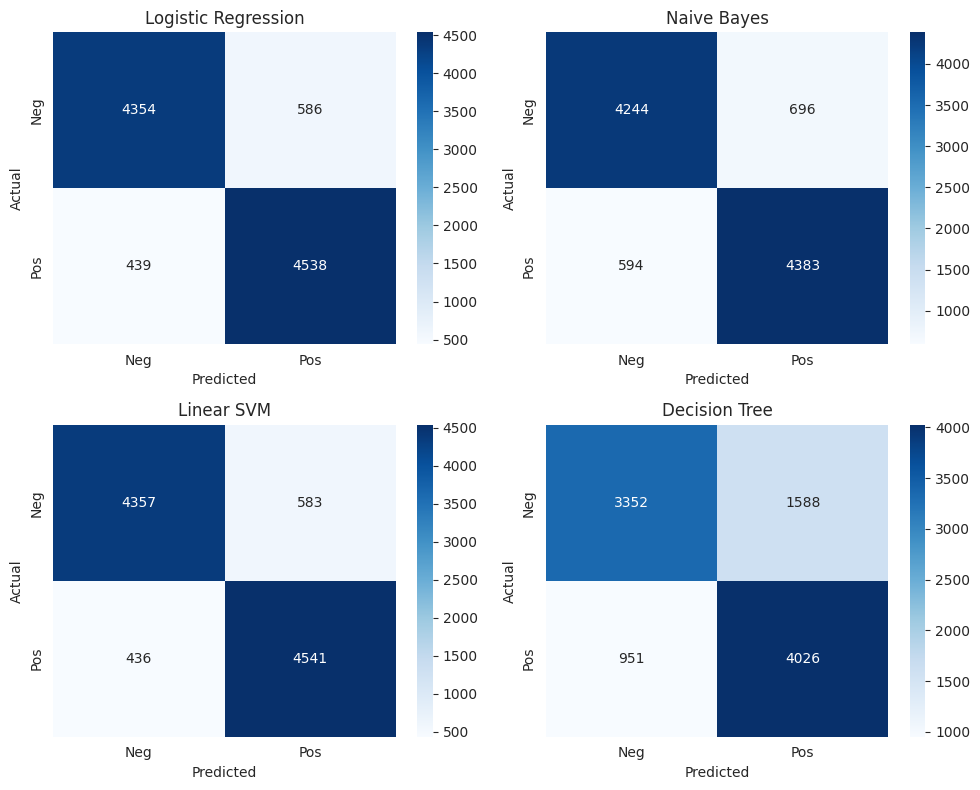

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### 7.2 Classification report of the best model

In [31]:
best = results_df.loc[0, "Model"]
print("Best model:", best)
print(classification_report(y_test, preds[best], target_names=["Negative", "Positive"]))

Best model: Linear SVM
              precision    recall  f1-score   support

    Negative       0.91      0.88      0.90      4940
    Positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



### 7.3 Most important words (Logistic Regression)
Words the model uses most to decide positive or negative.

In [32]:
lr = models["Logistic Regression"]
words = np.array(vec.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top_neg, top_pos = words[order[:15]], words[order[-15:]]
print("Top NEGATIVE words:", list(top_neg))
print("Top POSITIVE words:", list(top_pos))

Top NEGATIVE words: ['worst', 'awful', 'bad', 'boring', 'waste', 'poor', 'terrible', 'worse', 'horrible', 'dull', 'poorly', 'fails', 'disappointment', 'annoying', 'lame']
Top POSITIVE words: ['superb', 'hilarious', 'love', 'enjoyed', 'fun', 'today', 'brilliant', 'loved', 'favorite', 'wonderful', 'amazing', 'perfect', 'best', 'excellent', 'great']


## 8. Test with your own reviews

In [33]:
def predict_review(text, model_name="Logistic Regression"):
    X = vec.transform([clean_text(text)])
    return "Positive" if models[model_name].predict(X)[0] == 1 else "Negative"

tests = ["This movie was absolutely fantastic, great acting!",
         "Terrible film. Boring and a complete waste of time."]
for t in tests:
    print(t, "->", {n: predict_review(t, n) for n in models})

This movie was absolutely fantastic, great acting! -> {'Logistic Regression': 'Positive', 'Naive Bayes': 'Positive', 'Linear SVM': 'Positive', 'Decision Tree': 'Positive'}
Terrible film. Boring and a complete waste of time. -> {'Logistic Regression': 'Negative', 'Naive Bayes': 'Negative', 'Linear SVM': 'Negative', 'Decision Tree': 'Negative'}


## 9. Save the models for the Streamlit app
This downloads 3 files. Put them in the same folder as `app.py`.

In [34]:
joblib.dump(vec, "tfidf_vectorizer.joblib")
joblib.dump(models, "all_models.joblib")
joblib.dump(accs, "accuracies.joblib")
print("scikit-learn version:", sklearn.__version__)

files.download("tfidf_vectorizer.joblib")
files.download("all_models.joblib")
files.download("accuracies.joblib")

scikit-learn version: 1.6.1
Saved: tfidf_vectorizer.joblib
Saved: all_models.joblib
Saved: accuracies.joblib


## Conclusion
Use the results from this run to identify the best test accuracy, compare error types and discuss the validation experiments. These four models are alternatives, not an ensemble. A single validation split and mostly fixed preprocessing limit the conclusions. Each member owns one model experiment; shared preprocessing and frontend integration connect the contributions.